# Lesson 13: Clustering Titanic passengers

Compare distance-based clustering methods and graph communities using passenger features. Survival is retained only for descriptive comparison and is excluded from clustering. Run from this folder with pandas, NumPy, SciPy, scikit-learn, Matplotlib, seaborn, NetworkX, and python-louvain installed.

**Data:** [Titanic: Machine Learning from Disaster](https://www.kaggle.com/competitions/titanic/data). Download the labeled `train.csv`, rename it to `data_tms.csv`, and place it in this lesson folder.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data_tms.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
print(df['Survived'].value_counts())

Survived
0    549
1    342
Name: count, dtype: int64


In [3]:
df = df.dropna(subset=['Embarked']).reset_index(drop=True).copy()

In [4]:
titles = df["Name"].str.extract(r",\s*([^.]+)\.", expand=False).str.strip()
titles = titles.replace({"Ms": "Miss"})
df["Title"] = titles.where(titles.isin(["Mr", "Mrs", "Miss", "Master"]), "Other")
df["Age"] = df["Age"].fillna(df.groupby("Title")["Age"].transform("median"))
df["Age"] = df["Age"].fillna(df["Age"].median())

In [5]:
df['FamilySize'] = 1 + df['SibSp'] + df['Parch']
df['HasFamily'] = (df['FamilySize'] > 1).astype(int)

In [6]:
from sklearn.preprocessing import LabelEncoder

new_df = df[['Pclass', 'Sex', 'Age', 'Embarked', 'FamilySize']].copy()
le = LabelEncoder()
new_df['Sex'] = le.fit_transform(new_df['Sex'])

new_df = pd.get_dummies(new_df, columns=['Embarked'], prefix='Embarked')
new_df.head(10)

,Pclass,Sex,Age,FamilySize,Embarked_C,Embarked_Q,Embarked_S
0,3,1,22.0,2,False,False,True
1,1,0,38.0,2,True,False,False
2,3,0,26.0,1,False,False,True
3,1,0,35.0,2,False,False,True
4,3,1,35.0,1,False,False,True
5,3,1,30.0,1,False,True,False
6,1,1,54.0,1,False,False,True
7,3,1,2.0,5,False,False,True
8,3,0,27.0,3,False,False,True
9,2,0,14.0,2,True,False,False


In [7]:
from sklearn.preprocessing import StandardScaler
X = pd.DataFrame(StandardScaler().fit_transform(new_df), columns=new_df.columns, index=new_df.index)

## K-means, agglomerative clustering, and DBSCAN

Scale features before distance-based clustering. Silhouette scores describe separation in the feature space; they do not establish whether the groups represent meaningful social categories.

In [8]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans = KMeans(n_clusters=4, random_state=42)
labels_kmeans = kmeans.fit_predict(X)

sil_kmeans = silhouette_score(X, labels_kmeans)
print("Silhouette KMeans:", sil_kmeans)


Silhouette KMeans: 0.318043215600626


In [9]:
from sklearn.cluster import AgglomerativeClustering

agg = AgglomerativeClustering(n_clusters=2)
labels_agg = agg.fit_predict(X)

sil_agg = silhouette_score(X, labels_agg)
print("Silhouette Agglomerative:", sil_agg)

Silhouette Agglomerative: 0.3826836051431917


In [10]:
from sklearn.cluster import DBSCAN
import numpy as np
dbscan = DBSCAN(eps=1.3, min_samples=5)
labels_dbscan = dbscan.fit_predict(X)
mask = labels_dbscan != -1
n_clusters = len(set(labels_dbscan[mask]))
if 2 <= n_clusters < mask.sum():
    sil_dbscan = silhouette_score(X.loc[mask], labels_dbscan[mask])
    print("DBSCAN silhouette excluding noise:", sil_dbscan)
else:
    print("Silhouette unavailable: fewer than two non-noise clusters.")
print("Noise points:", (~mask).sum())

DBSCAN silhouette excluding noise: 0.3931834896289227
Noise points: 21


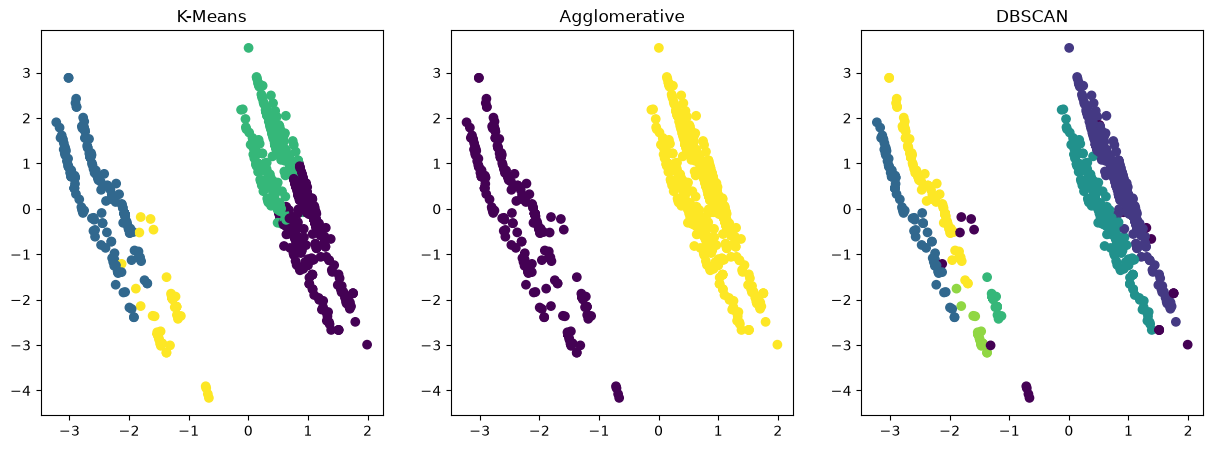

In [11]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.scatter(X_pca[:,0], X_pca[:,1], c=labels_kmeans)
plt.title('K-Means')

plt.subplot(1,3,2)
plt.scatter(X_pca[:,0], X_pca[:,1], c=labels_agg)
plt.title('Agglomerative')

plt.subplot(1,3,3)
plt.scatter(X_pca[:,0], X_pca[:,1], c=labels_dbscan)
plt.title('DBSCAN')

plt.show()


In [12]:
df['KMeans_Cluster'] = labels_kmeans
df['Agglomerative_Cluster'] = labels_agg
df['DBSCAN_Cluster'] = labels_dbscan

df[['Pclass', 'Sex', 'Age', 'FamilySize', 'Embarked', 'Survived', 'KMeans_Cluster', 'Agglomerative_Cluster', 'DBSCAN_Cluster']]

,Pclass,Sex,Age,FamilySize,Embarked,Survived,KMeans_Cluster,Agglomerative_Cluster,DBSCAN_Cluster
0,3,male,22.0,2,S,0,0,1,0
1,1,female,38.0,2,C,1,1,0,1
2,3,female,26.0,1,S,1,0,1,2
3,1,female,35.0,2,S,1,2,1,2
4,3,male,35.0,1,S,0,0,1,0
...,...,...,...,...,...,...,...,...,...
884,2,male,27.0,1,S,0,0,1,0
885,1,female,19.0,1,S,1,2,1,2
886,3,female,21.0,4,S,0,0,1,2
887,1,male,26.0,1,C,1,1,0,5


## Choosing cluster counts

Compare inertia and silhouette scores over several values of k. These diagnostics can suggest candidates, but do not prove that a particular number of clusters is correct.

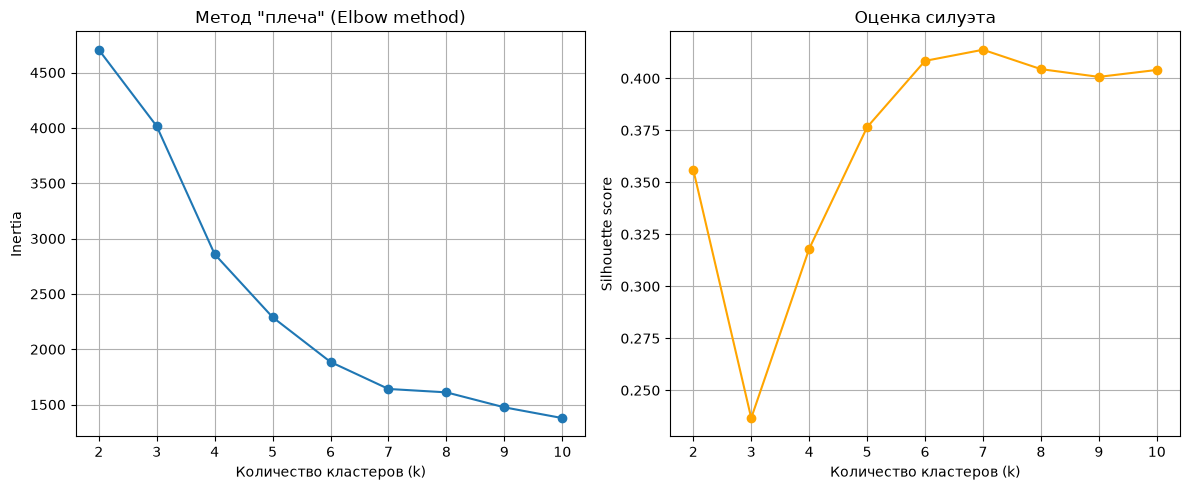

In [13]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertias = []
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    labels = kmeans.fit_predict(X)
    inertias.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(X, labels))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].plot(K_range, inertias, marker='o')
ax[0].set_title('Метод "плеча" (Elbow method)')
ax[0].set_xlabel('Количество кластеров (k)')
ax[0].set_ylabel('Inertia')
ax[0].grid(True)

ax[1].plot(K_range, silhouette_scores, marker='o', color='orange')
ax[1].set_title('Оценка силуэта')
ax[1].set_xlabel('Количество кластеров (k)')
ax[1].set_ylabel('Silhouette score')
ax[1].grid(True)

plt.tight_layout()
plt.show()


In [14]:
from sklearn.cluster import KMeans
import pandas as pd
import numpy as np

optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
labels = kmeans.fit_predict(X)

clustered_df = new_df.copy()
clustered_df['Cluster'] = labels

cluster_summary = clustered_df.groupby('Cluster').mean(numeric_only=True)

print("Средние значения признаков по кластерам:")
print(cluster_summary)

print("\nРазмеры кластеров:")
print(clustered_df['Cluster'].value_counts())


Средние значения признаков по кластерам:
           Pclass       Sex        Age  FamilySize  Embarked_C  Embarked_Q  \
Cluster                                                                      
0        2.834568  0.743210  23.870988    2.192593         0.0         0.0   
1        1.886905  0.565476  30.511429    1.750000         1.0         0.0   
2        1.531381  0.585774  38.648536    1.631799         0.0         0.0   
3        2.909091  0.532468  26.681818    1.597403         0.0         1.0   

         Embarked_S  
Cluster              
0               1.0  
1               0.0  
2               1.0  
3               0.0  

Размеры кластеров:
Cluster
0    405
2    239
1    168
3     77
Name: count, dtype: int64


## Agglomerative clustering

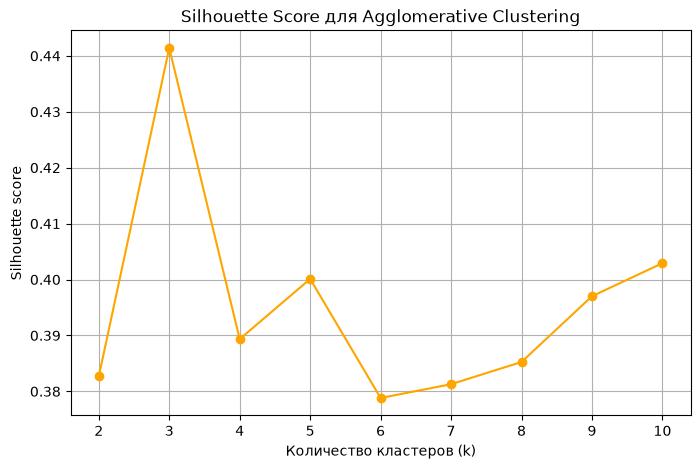

Оптимальное число кластеров: 3, silhouette = 0.441


In [15]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    agg = AgglomerativeClustering(n_clusters=k)
    labels = agg.fit_predict(X)
    score = silhouette_score(X, labels)
    silhouette_scores.append(score)

plt.figure(figsize=(8,5))
plt.plot(K_range, silhouette_scores, marker='o', color='orange')
plt.title('Silhouette Score для Agglomerative Clustering')
plt.xlabel('Количество кластеров (k)')
plt.ylabel('Silhouette score')
plt.grid(True)
plt.show()

best_k = K_range[silhouette_scores.index(max(silhouette_scores))]
print(f"Оптимальное число кластеров: {best_k}, silhouette = {max(silhouette_scores):.3f}")


In [16]:
from sklearn.cluster import AgglomerativeClustering

agg = AgglomerativeClustering(n_clusters=2)
labels_agg = agg.fit_predict(X)

sil_agg = silhouette_score(X, labels_agg)
print("Silhouette Agglomerative:", sil_agg)

Silhouette Agglomerative: 0.3826836051431917


In [17]:
clustered_df = new_df.copy()
clustered_df['Cluster'] = labels_agg

cluster_summary = clustered_df.groupby('Cluster').mean(numeric_only=True)

print("Средние значения признаков по кластерам:")
print(cluster_summary)

print("\nРазмеры кластеров:")
print(clustered_df['Cluster'].value_counts())


Средние значения признаков по кластерам:
           Pclass       Sex        Age  FamilySize  Embarked_C  Embarked_Q  \
Cluster                                                                      
0        2.208163  0.555102  29.307837    1.702041    0.685714    0.314286   
1        2.350932  0.684783  29.355202    1.984472    0.000000    0.000000   

         Embarked_S  
Cluster              
0               0.0  
1               1.0  

Размеры кластеров:
Cluster
1    644
0    245
Name: count, dtype: int64


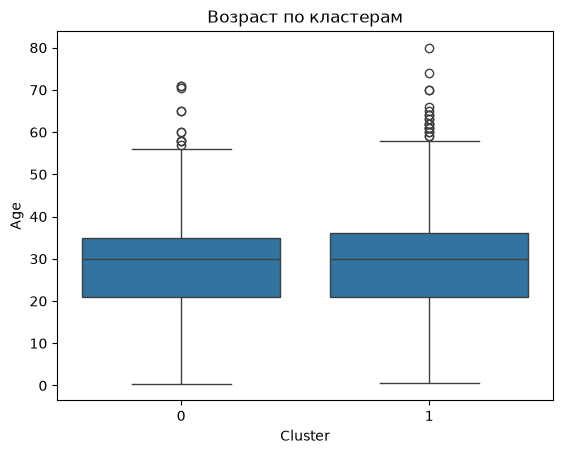

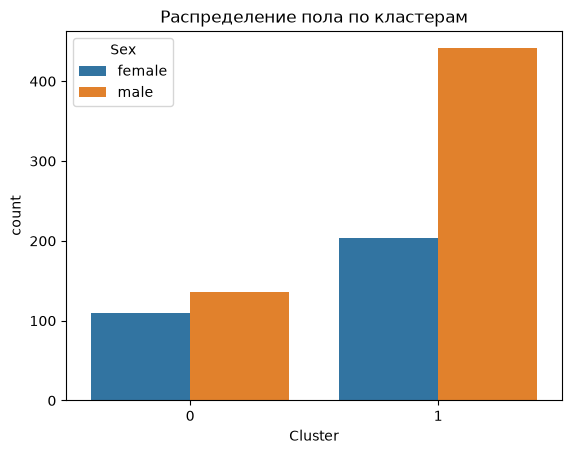

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.boxplot(x='Cluster', y='Age', data=clustered_df)
plt.title('Возраст по кластерам')
plt.show()

sns.countplot(x='Cluster', hue='Sex', data=clustered_df.replace({'Sex': {0: 'female', 1: 'male'}}))
plt.title('Распределение пола по кластерам')
plt.show()


## Spectral clustering

~/Documents/Codex/2026-11-05/new-chat/work/lesson5-venv/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
~/Documents/Codex/2026-11-05/new-chat/work/lesson5-venv/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
~/Documents/Codex/2026-11-05/new-chat/work/lesson5-venv/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
~/Documents/Codex/2026-11-05/new-chat/work/lesson5-venv/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
~/Documents/Codex/2026-11-05/new-chat/work/lesson5-venv/lib/

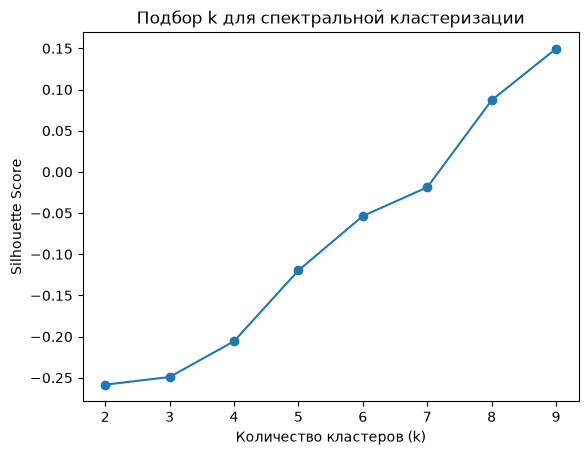

Оптимальное k по силуэту: 9


In [19]:
from sklearn.cluster import SpectralClustering
from sklearn.metrics import silhouette_score
import numpy as np

sil_scores = []
k_values = range(2, 10)

for k in k_values:
    spectral = SpectralClustering(
        n_clusters=k,
        affinity='nearest_neighbors',
        assign_labels='kmeans',
        random_state=42
    )
    labels = spectral.fit_predict(X)
    score = silhouette_score(X, labels)
    sil_scores.append(score)

import matplotlib.pyplot as plt

plt.plot(k_values, sil_scores, marker='o')
plt.xlabel('Количество кластеров (k)')
plt.ylabel('Silhouette Score')
plt.title('Подбор k для спектральной кластеризации')
plt.show()

optimal_k = k_values[np.argmax(sil_scores)]
print(f"Оптимальное k по силуэту: {optimal_k}")


In [20]:
from sklearn.cluster import SpectralClustering
import pandas as pd

optimal_k = 4  # число кластеров

# создаём и обучаем спектральную модель
spectral = SpectralClustering(
    n_clusters=optimal_k,
    affinity='nearest_neighbors',  # можно 'rbf' или 'nearest_neighbors'
    assign_labels='kmeans',        # алгоритм назначения меток
    random_state=42
)
labels = spectral.fit_predict(X)

# добавляем метки в DataFrame
clustered_df = new_df.copy()
clustered_df['Cluster'] = labels

# вычисляем средние значения признаков по каждому кластеру
cluster_summary = clustered_df.groupby('Cluster').mean(numeric_only=True)

print("Средние значения признаков по кластерам:")
print(cluster_summary)

print("\nРазмеры кластеров:")
print(clustered_df['Cluster'].value_counts())

Средние значения признаков по кластерам:
           Pclass       Sex        Age  FamilySize  Embarked_C  Embarked_Q  \
Cluster                                                                      
0        2.323760  0.592689  29.259465    1.986945      0.0953    0.100522   
1        2.010526  1.000000  31.778105    1.526316      1.0000    0.000000   
2        3.000000  1.000000  24.205882    1.000000      0.0000    0.000000   
3        3.000000  1.000000  22.000000    1.000000      0.0000    0.000000   

         Embarked_S  
Cluster              
0          0.804178  
1          0.000000  
2          1.000000  
3          1.000000  

Размеры кластеров:
Cluster
0    766
1     95
2     17
3     11
Name: count, dtype: int64


~/Documents/Codex/2026-11-05/new-chat/work/lesson5-venv/lib/python3.11/site-packages/sklearn/manifold/_spectral_embedding.py:325: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


## Graph communities

Build a nearest-neighbor graph from the scaled feature vectors and compare Louvain and label propagation communities.

In [21]:
import networkx as nx
from sklearn.neighbors import kneighbors_graph
from community import community_louvain  # пакет python-louvain
import pandas as pd

knn_graph = kneighbors_graph(X, n_neighbors=10, include_self=False)
G = nx.from_scipy_sparse_array(knn_graph)

partition = community_louvain.best_partition(G, random_state=42)

clustered_df = new_df.copy()
clustered_df['Community'] = pd.Series(partition, index=clustered_df.index)

community_summary = clustered_df.groupby('Community').mean(numeric_only=True)

print("Средние значения признаков по сообществам:")
print(community_summary)

print("\nРазмеры сообществ:")
print(clustered_df['Community'].value_counts())


Средние значения признаков по сообществам:
             Pclass  Sex        Age  FamilySize  Embarked_C  Embarked_Q  \
Community                                                                 
0          2.680000  1.0  19.915000    2.860000         0.0         0.0   
1          3.000000  1.0  25.777778    1.000000         0.0         0.0   
2          2.988636  0.0  22.954545    3.295455         0.0         0.0   
3          1.000000  0.0  34.204545    1.977273         0.0         0.0   
4          3.000000  1.0  40.482456    1.035088         0.0         0.0   
5          2.926829  1.0  30.365854    1.731707         0.0         1.0   
6          1.013158  1.0  41.664474    1.434211         0.0         0.0   
7          3.000000  1.0  11.304348    7.173913         0.0         0.0   
8          3.000000  1.0  17.880000    1.000000         0.0         0.0   
9          1.726027  0.0  28.863014    2.041096         1.0         0.0   
10         3.000000  1.0  20.568182    1.000000         0

In [22]:
import networkx as nx
from sklearn.neighbors import kneighbors_graph
import pandas as pd

knn_graph = kneighbors_graph(X, n_neighbors=10, include_self=False)
G = nx.from_scipy_sparse_array(knn_graph)

communities = nx.algorithms.community.label_propagation_communities(G)

labels = {}
for i, community in enumerate(communities):
    for node in community:
        labels[node] = i

clustered_df = new_df.copy()
clustered_df['LP_Community'] = pd.Series(labels, index=clustered_df.index)

lp_summary = clustered_df.groupby('LP_Community').mean(numeric_only=True)
print("Средние признаки по сообществам Label Propagation:")
print(lp_summary)

print("\nРазмеры сообществ:")
print(clustered_df['LP_Community'].value_counts())

Средние признаки по сообществам Label Propagation:
                Pclass       Sex        Age  FamilySize  Embarked_C  \
LP_Community                                                          
0             2.609756  1.000000  15.884146    2.731707         0.0   
1             1.000000  0.000000  43.333333    1.740741         1.0   
2             3.000000  0.000000  24.379310    1.000000         0.0   
3             1.000000  0.000000  36.333333    2.190476         0.0   
4             3.000000  1.000000  32.909091    1.000000         0.0   
5             2.967742  1.000000  33.225806    1.064516         0.0   
6             1.000000  1.000000  61.692308    1.153846         0.0   
7             3.000000  1.000000   7.441176    6.470588         0.0   
8             2.971429  0.028571  23.600000    5.314286         0.0   
9             2.793103  0.000000  19.068966    2.413793         1.0   
10            3.000000  0.000000  21.045455    2.227273         0.0   
11            1.111111  0.

## Spectral clustering from scratch

Construct an affinity matrix, normalize its Laplacian, and cluster the leading eigenvectors.

In [23]:
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist
from scipy.linalg import eigh

X = (X - X.mean(axis=0)) / X.std(axis=0)

n_samples = X.shape[0]
k_clusters = 4
sigma = 1.0

distances = cdist(X, X, 'sqeuclidean')
W = np.exp(-distances / (2 * sigma**2))

D = np.diag(W.sum(axis=1))

D_inv_sqrt = np.diag(1.0 / np.sqrt(W.sum(axis=1)))
L_sym = np.eye(n_samples) - D_inv_sqrt @ W @ D_inv_sqrt

eigvals, eigvecs = eigh(L_sym)
X_spec = eigvecs[:, :k_clusters]

def kmeans(X, k, n_iters=100):
    n_samples, n_features = X.shape
    rng = np.random.default_rng(42)
    centroids = X[rng.choice(n_samples, k, replace=False)]

    for _ in range(n_iters):
        # Расстояния до центроидов
        dists = np.linalg.norm(X[:, None] - centroids[None, :], axis=2)
        labels = np.argmin(dists, axis=1)
        # Обновление центроидов
        for i in range(k):
            if np.any(labels == i):
                centroids[i] = X[labels == i].mean(axis=0)
    return labels

labels = kmeans(X_spec, k_clusters)

clustered_df = new_df.copy()
clustered_df['Cluster'] = labels

print("Средние значения признаков по кластерам:")
print(clustered_df.groupby('Cluster').mean(numeric_only=True))
print("\nРазмеры кластеров:")
print(clustered_df['Cluster'].value_counts())


Средние значения признаков по кластерам:
           Pclass       Sex        Age  FamilySize  Embarked_C  Embarked_Q  \
Cluster                                                                      
0        1.975806  0.463710  32.610887    1.737903    0.000000    0.000000   
1        2.775735  1.000000  27.797794    1.121324    0.000000    0.000000   
2        2.209205  0.552301  28.752803    1.686192    0.702929    0.297071   
3        2.169231  0.446154  27.421154    4.276923    0.000000    0.046154   

         Embarked_S  
Cluster              
0          1.000000  
1          1.000000  
2          0.000000  
3          0.953846  

Размеры кластеров:
Cluster
1    272
0    248
2    239
3    130
Name: count, dtype: int64
